# **1. 캐글**
캐글(Kaggle)은 데이터 과학자와 머신러닝 엔지니어들이 학습, 협업, 경쟁할 수 있는 온라인 플랫폼입니다. 구글에 소속된 이 플랫폼은 다양한 데이터셋과 머신러닝 문제를 제공하며, 사용자들이 자신의 모델을 개발하고 성능을 경쟁적으로 평가받을 수 있는 경진대회도 열립니다. 초보자는 데이터를 다루는 실습을 하고, 경험 많은 전문가들은 포트폴리오를 확장하거나 상금을 받을 기회를 얻을 수 있습니다. 또한, 커뮤니티 포럼과 튜토리얼, 노트북 공유를 통해 지식을 공유하고 학습할 수 있는 환경을 제공합니다. 캐글은 데이터 분석과 머신러닝을 배우고 실제 문제에 적용해 보고 싶은 사람들에게 유용한 플랫폼입니다.

# **2. Online Retail**

```
InvoiceNo: 주문 번호
StockCode: 상품 코드
Description: 상품 설명
Quantity: 주문 수량
InvoiceDate: 주문 날짜
Price: 상품 가격
Customer ID: 고객 아이디
Country: 고객 거주지역(국가)
retail.columns
```

In [19]:
import pandas as pd

In [20]:
retail = pd.read_csv('./data/online_retail_II.csv')
retail

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [21]:
retail.info() # 1067371개의 데이터
# 총 8개의 컬럼
# null값 check
# null값이 있으므로 

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [22]:
retail.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [23]:
len(retail)

1067371

In [24]:
# 각 컬럼당 null이 몇 개 있는지 확인
retail.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [25]:
# 각 컬럼당 null이 얼마나 있는지 비율 확인
retail.isnull().mean()

Invoice        0.000000
StockCode      0.000000
Description    0.004105
Quantity       0.000000
InvoiceDate    0.000000
Price          0.000000
Customer ID    0.227669
Country        0.000000
dtype: float64

In [26]:
retail['Customer ID']

0          13085.0
1          13085.0
2          13085.0
3          13085.0
4          13085.0
            ...   
1067366    12680.0
1067367    12680.0
1067368    12680.0
1067369    12680.0
1067370    12680.0
Name: Customer ID, Length: 1067371, dtype: float64

In [27]:
# 비회원/탈퇴/휴면회원 제거
retail = retail[pd.notnull(retail['Customer ID'])] # null값이 없는 사람만 추출
retail

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [28]:
len(retail)

824364

In [29]:
# 구입 수량이 0 이하인 데이터를 확인
retail[retail['Quantity'] <= 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
1067002,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [30]:
# 구입 수량이 1이상인 데이터만 저장
retail = retail[retail['Quantity'] >= 1]
len(retail)

805620

In [31]:
# 구입 수량이 0 이하인 데이터를 확인
retail[retail['Price'] <= 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
...,...,...,...,...,...,...,...,...
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.0,15602.0,United Kingdom
1005014,577168,M,Manual,1,2011-11-18 10:42:00,0.0,12603.0,Germany
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.0,12444.0,Norway
1011446,577696,M,Manual,1,2011-11-21 11:57:00,0.0,16406.0,United Kingdom


In [32]:
# 구입 가격이 0보다 큰 데이터만 저장
retail = retail[retail['Price'] > 0]
len(retail)

805549

In [33]:
# 고객의 총 지출비용(CheckoutPrice) 파생변수 만들기
# 총 지출비용(CheckoutPrice) = 가격(Price) * 수량(Quantity)
retail['CheckoutPrice'] = retail['Price'] * retail['Quantity']
retail

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,CheckoutPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [34]:
retail.info()

<class 'pandas.DataFrame'>
Index: 805549 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Invoice        805549 non-null  str    
 1   StockCode      805549 non-null  str    
 2   Description    805549 non-null  str    
 3   Quantity       805549 non-null  int64  
 4   InvoiceDate    805549 non-null  str    
 5   Price          805549 non-null  float64
 6   Customer ID    805549 non-null  float64
 7   Country        805549 non-null  str    
 8   CheckoutPrice  805549 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 61.5 MB


In [35]:
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])
retail.info()

<class 'pandas.DataFrame'>
Index: 805549 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Invoice        805549 non-null  str           
 1   StockCode      805549 non-null  str           
 2   Description    805549 non-null  str           
 3   Quantity       805549 non-null  int64         
 4   InvoiceDate    805549 non-null  datetime64[us]
 5   Price          805549 non-null  float64       
 6   Customer ID    805549 non-null  float64       
 7   Country        805549 non-null  str           
 8   CheckoutPrice  805549 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 61.5 MB


In [36]:
# 전체 매출
total_revenue = retail['CheckoutPrice'].sum()
total_revenue

np.float64(17743429.178000003)

In [41]:
# 각 나라별 구매 횟수
pd.options.display.max_rows = 50
# value_counts(): 객체의 각 고유값(유니크 값)의 개수를 계산하고, 이를 내림차순으로 정렬해 반환하는 함수
retail['Country'].value_counts()

Country
United Kingdom          725250
Germany                  16694
EIRE                     15743
France                   13812
Netherlands               5088
Spain                     3719
Belgium                   3068
Switzerland               3011
Portugal                  2446
Australia                 1812
Channel Islands           1569
Italy                     1468
Norway                    1436
Sweden                    1319
Cyprus                    1155
Finland                   1032
Austria                    922
Denmark                    798
Greece                     657
Unspecified                521
Poland                     512
Japan                      485
USA                        409
United Arab Emirates       383
Singapore                  339
Israel                     322
Malta                      282
Iceland                    253
Canada                     228
Lithuania                  189
RSA                        122
Brazil                      94


In [42]:
# 국가별 매출
rev_by_countries = retail.groupby('Country')['CheckoutPrice'].sum().sort_values()
rev_by_countries

Country
Nigeria                 1.403900e+02
Saudi Arabia            1.459200e+02
West Indies             5.364100e+02
Czech Republic          8.267400e+02
Korea                   1.118510e+03
European Community      1.300250e+03
Bahrain                 1.354370e+03
Brazil                  1.411870e+03
Lebanon                 1.693880e+03
RSA                     1.933740e+03
Thailand                3.070540e+03
Canada                  4.883040e+03
Iceland                 5.633320e+03
Lithuania               6.553740e+03
Malta                   8.099090e+03
USA                     8.366860e+03
Unspecified             8.613650e+03
United Arab Emirates    9.202690e+03
Israel                  1.042109e+04
Poland                  1.090245e+04
Greece                  1.909619e+04
Austria                 2.361301e+04
Cyprus                  2.498013e+04
Singapore               2.531706e+04
Finland                 2.992554e+04
Italy                   3.255042e+04
Channel Islands         4.4996

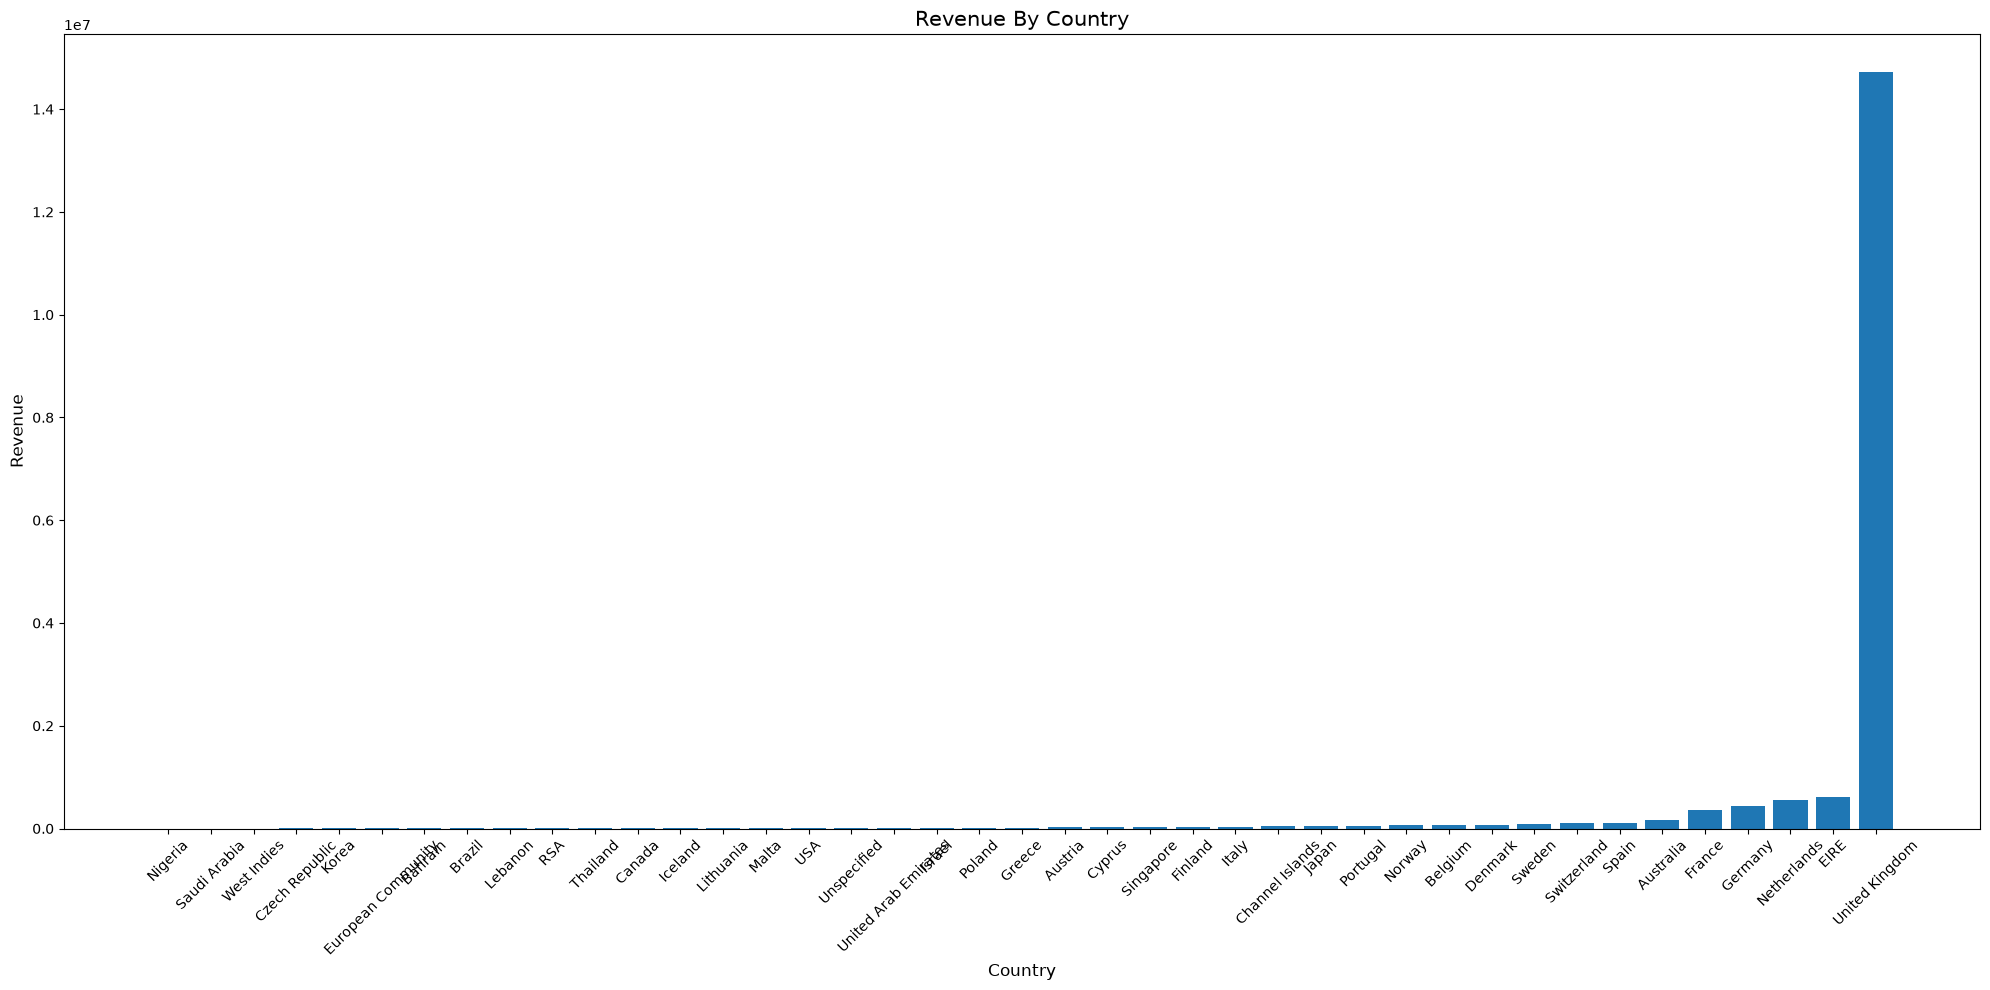

In [44]:
import matplotlib.pyplot as plt

# matplotlib 객체 생성
# 그래프를 그릴 축(ax)과 그림(fig)을 생성
fig, ax = plt.subplots(figsize=(20, 10))

# 막대 그래프 그리기
ax.bar(rev_by_countries.index, rev_by_countries.values)

# 라벨 설정
ax.set_xlabel('Country', fontsize=12)
ax.set_ylabel('Revenue', fontsize=12)
ax.set_title('Revenue By Country', fontsize=15)

# x축 눈금 라벨 회전
ax.set_xticks(range(len(rev_by_countries.index)))
ax.set_xticklabels(rev_by_countries.index, rotation=45)

# 그래프 출력
# 래프와 텍스트가 잘리지 않고 보기 좋게 배치되도록 자동으로 여백을 조정하는 유용한 함수
plt.tight_layout()
plt.show()

In [45]:
rev_by_countries / total_revenue

Country
Nigeria                 0.000008
Saudi Arabia            0.000008
West Indies             0.000030
Czech Republic          0.000047
Korea                   0.000063
European Community      0.000073
Bahrain                 0.000076
Brazil                  0.000080
Lebanon                 0.000095
RSA                     0.000109
Thailand                0.000173
Canada                  0.000275
Iceland                 0.000317
Lithuania               0.000369
Malta                   0.000456
USA                     0.000472
Unspecified             0.000485
United Arab Emirates    0.000519
Israel                  0.000587
Poland                  0.000614
Greece                  0.001076
Austria                 0.001331
Cyprus                  0.001408
Singapore               0.001427
Finland                 0.001687
Italy                   0.001835
Channel Islands         0.002536
Japan                   0.002657
Portugal                0.003229
Norway                  0.003388
Be

In [46]:
# 월별 매출 구하기
retail['InvoiceDate'].sort_values(ascending=False)

1067370   2011-12-09 12:50:00
1067362   2011-12-09 12:50:00
1067355   2011-12-09 12:50:00
1067357   2011-12-09 12:50:00
1067358   2011-12-09 12:50:00
                  ...        
5         2009-12-01 07:45:00
4         2009-12-01 07:45:00
3         2009-12-01 07:45:00
2         2009-12-01 07:45:00
0         2009-12-01 07:45:00
Name: InvoiceDate, Length: 805549, dtype: datetime64[us]

In [47]:
# 2011-12-09 12:50:00
# 2011-09-09 12:50:00
# date.month > 12
# date.month > 9
# 201112
# 201109

def extract_month(date):
    month = str(date.month)
    if date.month < 10:
        month = '0' + month
    return str(date.year) + month

In [ ]:
# InvoiceDate 데이터를 extract_month 함수를 통해 그룹을 맺어 값을 뽑고 CheckoutPrice의 값을 합친다.
rev_by_month = retail.set_index('InvoiceDate').groupby(extract_month)['CheckoutPrice'].sum()
rev_by_month

InvoiceDate
200912     686654.160
201001     557319.062
201002     506371.066
201003     699608.991
201004     594609.192
201005     599985.790
201006     639066.580
201007     591636.740
201008     604242.650
201009     831615.001
201010    1036680.000
201011    1172336.042
201012     884591.890
201101     569445.040
201102     447137.350
201103     595500.760
201104     469200.361
201105     678594.560
201106     661213.690
201107     600091.011
201108     645343.900
201109     952838.382
201110    1039318.790
201111    1161817.380
201112     518210.790
Name: CheckoutPrice, dtype: float64

In [65]:
def plot_bar(df, xlabel, ylabel, title, figsize=(12, 6), fontsize=12, titlesize=15, rotation=45):
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(df.index, df.values)
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=titlesize)
    ax.set_xticks(df.index)
    ax.set_xticklabels(df.index, rotation=rotation, fontsize=fontsize)
    plt.tight_layout()
    plt.show()

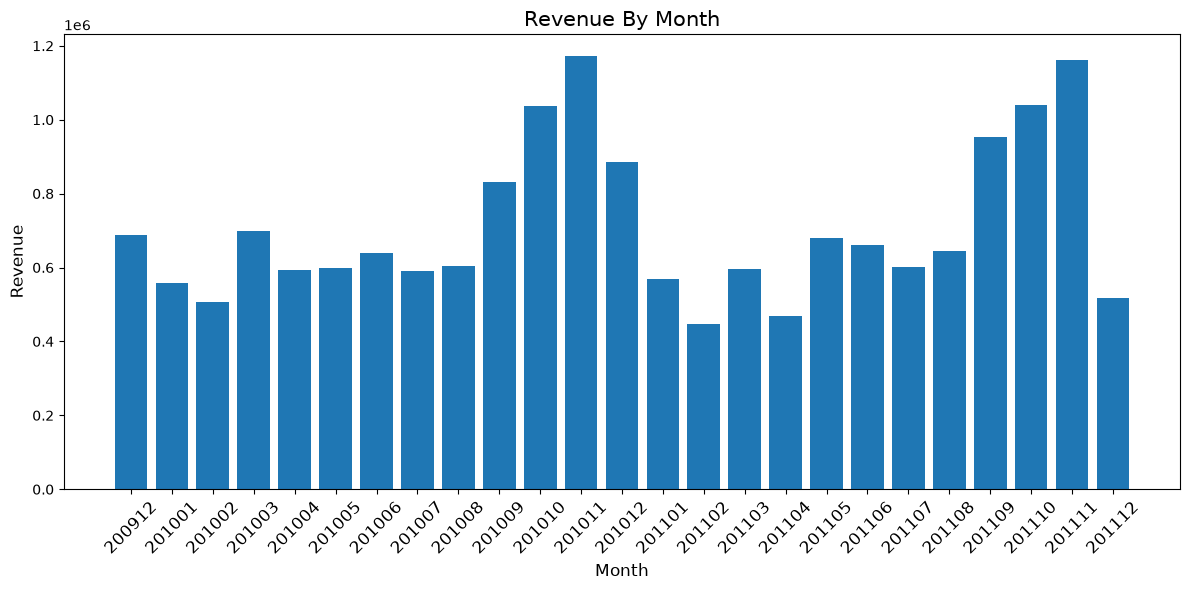

In [66]:
plot_bar(rev_by_month, 'Month', 'Revenue', 'Revenue By Month')

In [58]:
# 요일별 매출 구하기
def extract_dow(date):
    return date.dayofweek

In [59]:
rev_by_dow = retail.set_index('InvoiceDate').groupby(lambda date: date.dayofweek)['CheckoutPrice'].sum()
rev_by_dow

InvoiceDate
0    2817407.806
1    3384678.832
2    3115619.693
3    3841082.962
4    2758423.493
5       9803.050
6    1816413.342
Name: CheckoutPrice, dtype: float64

In [60]:
import numpy as np

DAY_OF_WEEK = np.array(['Mon', 'Tue', 'Web', 'Thur', 'Fri', 'Sat', 'Sun'])
rev_by_dow.index = DAY_OF_WEEK[rev_by_dow.index]
rev_by_dow.index

Index(['Mon', 'Tue', 'Web', 'Thur', 'Fri', 'Sat', 'Sun'], dtype='str')

In [61]:
rev_by_dow

Mon     2817407.806
Tue     3384678.832
Web     3115619.693
Thur    3841082.962
Fri     2758423.493
Sat        9803.050
Sun     1816413.342
Name: CheckoutPrice, dtype: float64

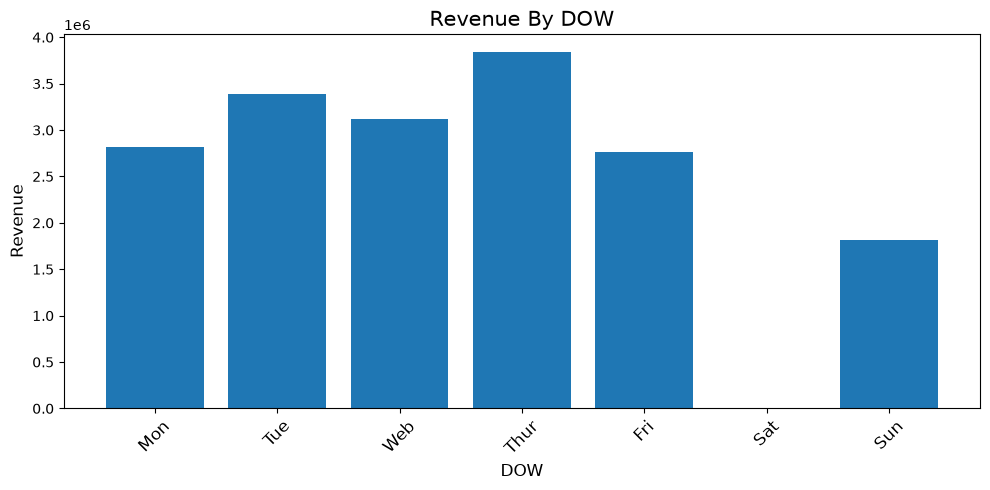

In [62]:
plot_bar(rev_by_dow, 'DOW', 'Revenue', 'Revenue By DOW')

In [67]:
# 시간대별 매출 구하기
rev_by_hour = retail.set_index('InvoiceDate').groupby(lambda date: date.hour)['CheckoutPrice'].sum()
rev_by_hour

InvoiceDate
6           4.250
7       76212.570
8      528877.660
9     1509659.881
10    2360784.823
11    2271810.993
12    2750224.631
13    2401116.924
14    1995849.271
15    1882943.792
16    1109616.461
17     495200.732
18     194533.670
19     126979.280
20      39614.240
Name: CheckoutPrice, dtype: float64

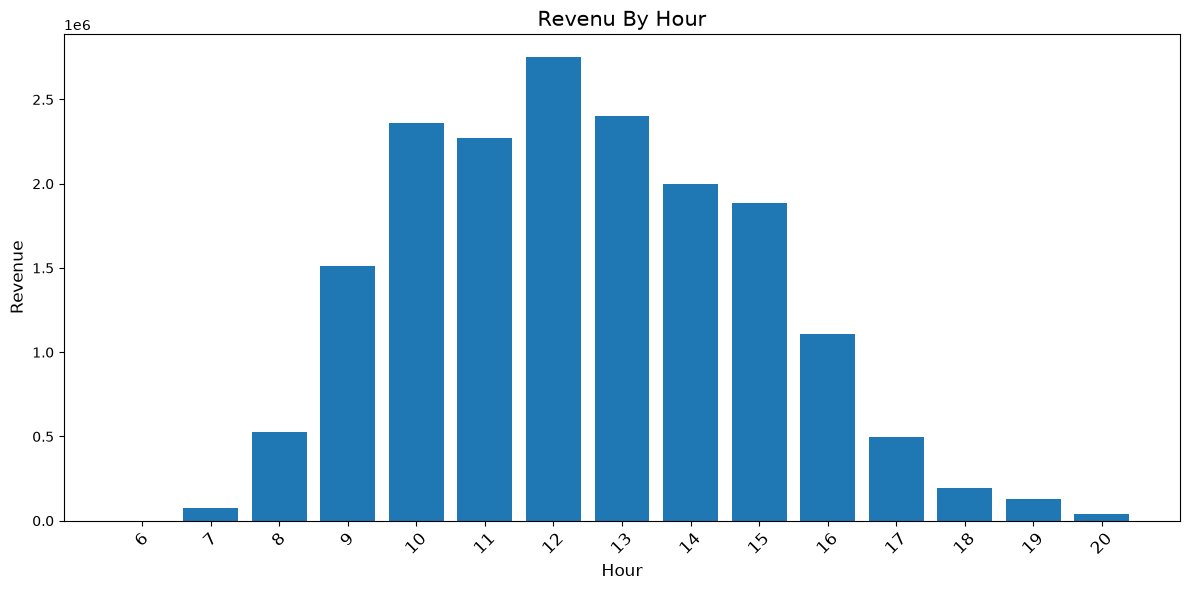

In [68]:
plot_bar(rev_by_hour, 'Hour', 'Revenue', 'Revenu By Hour')